In [21]:
#导入必要库
import cv2
import numpy as np
import matplotlib.pyplot as plt
import os

img_a(p1) h,w = (3072, 2316)
img_b(p2) h,w = (1697, 1279)


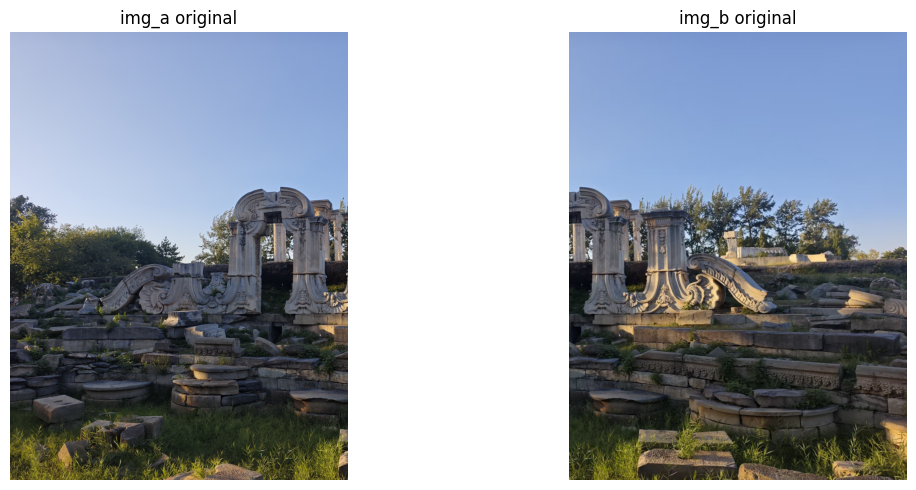

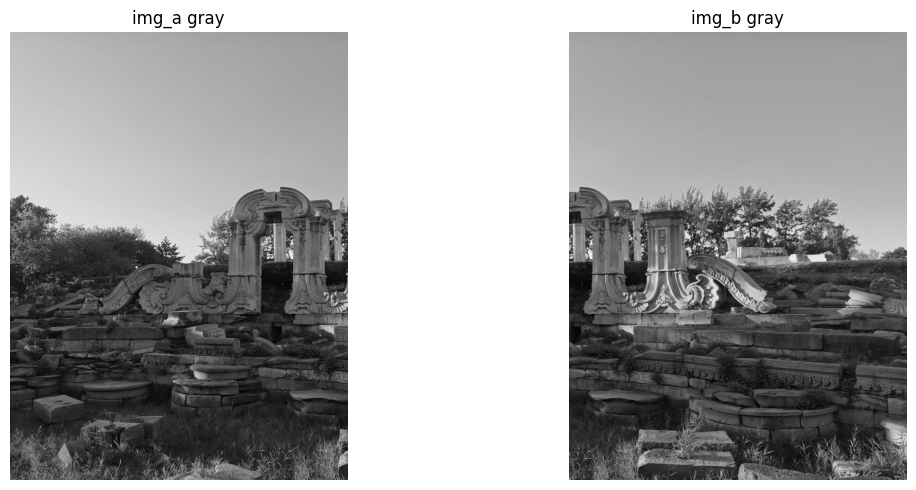

In [22]:
#使用原始裁切图片，保留尺寸差异
# 读取图像
img_a = cv2.imread("p1.jpg")
img_b = cv2.imread("p2.jpg")

print(f"img_a(p1) h,w = {img_a.shape[:2]}")
print(f"img_b(p2) h,w = {img_b.shape[:2]}")

gray_a = cv2.cvtColor(img_a, cv2.COLOR_BGR2GRAY)
gray_b = cv2.cvtColor(img_b, cv2.COLOR_BGR2GRAY)

# 可视化彩色原图
plt.figure(figsize=(13,5))
plt.subplot(1,2,1)
plt.imshow(cv2.cvtColor(img_a, cv2.COLOR_BGR2RGB))
plt.title("img_a original")
plt.axis("off")

plt.subplot(1,2,2)
plt.imshow(cv2.cvtColor(img_b, cv2.COLOR_BGR2RGB))
plt.title("img_b original")
plt.axis("off")
plt.tight_layout()
plt.savefig(os.path.join("result","input_rgb_raw.jpg"),bbox_inches="tight")
plt.show()

# 可视化灰度图
plt.figure(figsize=(13,5))
plt.subplot(1,2,1)
plt.imshow(gray_a, cmap="gray")
plt.title("img_a gray")
plt.axis("off")

plt.subplot(1,2,2)
plt.imshow(gray_b, cmap="gray")
plt.title("img_b gray")
plt.axis("off")
plt.tight_layout()
plt.savefig(os.path.join("result","input_gray_raw.jpg"),bbox_inches="tight")
plt.show()


=== 特征匹配统计 ===
初始匹配点对数: 49470
筛选后优质匹配点对数: 1106
优质匹配占比: 2.24%


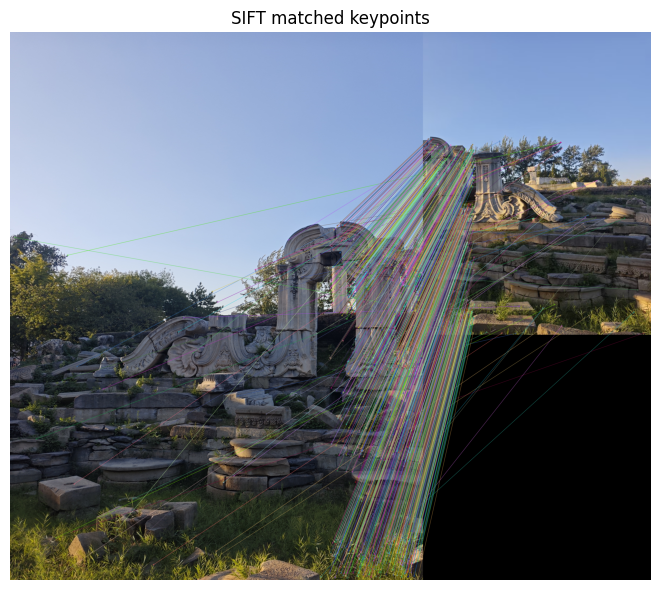

In [25]:
#关键点检测、特征匹配
sift = cv2.SIFT_create()
kp_a, des_a = sift.detectAndCompute(gray_a, None)
kp_b, des_b = sift.detectAndCompute(gray_b, None)

bf = cv2.BFMatcher()
matches = bf.knnMatch(des_a, des_b, k=2)

good_matches = []
for m, n in matches:
    if m.distance < 0.7 * n.distance:
        good_matches.append(m)

print("=== 特征匹配统计 ===")
print(f"初始匹配点对数: {len(matches)}")
print(f"筛选后优质匹配点对数: {len(good_matches)}")
if len(matches) > 0:
    print(f"优质匹配占比: {len(good_matches)/len(matches):.2%}")

matched_img = cv2.drawMatches(
    img_a, kp_a, img_b, kp_b, good_matches,
    None, flags=cv2.DrawMatchesFlags_NOT_DRAW_SINGLE_POINTS
)

plt.figure(figsize=(16,6))
plt.imshow(cv2.cvtColor(matched_img, cv2.COLOR_BGR2RGB))
plt.title("SIFT matched keypoints")
plt.axis("off")
plt.tight_layout()
plt.savefig(os.path.join("result","matched_keypoints_1.jpg"),bbox_inches="tight")
plt.show()



得到单应矩阵H:
[[ 1.80682837e+00 -1.61929367e-04  1.78012768e+03]
 [-1.42686536e-03  1.80876266e+00  5.44366165e-01]
 [-7.68889296e-07 -7.64359048e-08  1.00000000e+00]]


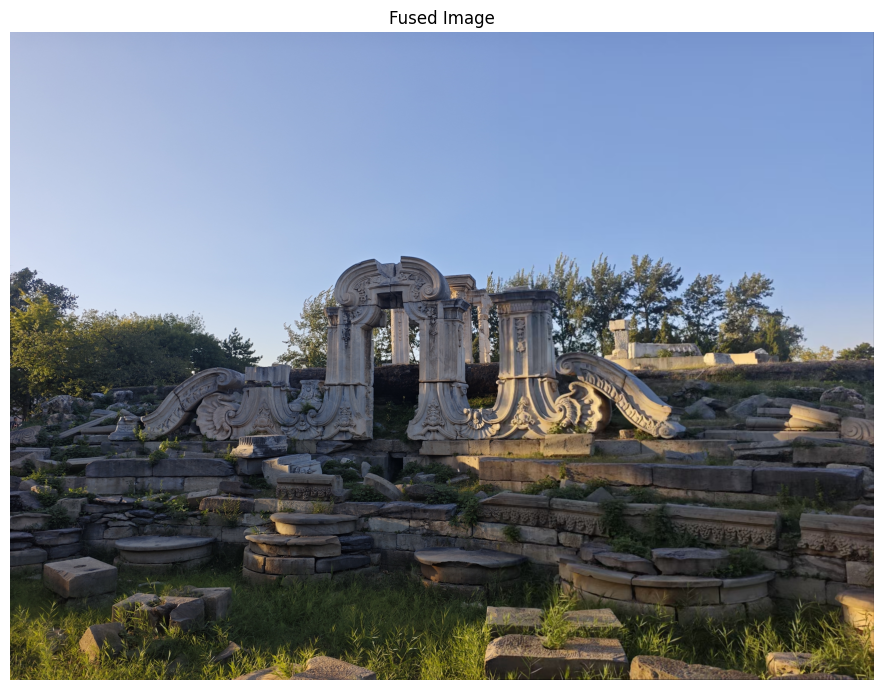

In [26]:
#图像拼接
src_pts = np.float32([kp_b[m.trainIdx].pt for m in good_matches]).reshape(-1,1,2)
dst_pts = np.float32([kp_a[m.queryIdx].pt for m in good_matches]).reshape(-1,1,2)

H, mask = cv2.findHomography(src_pts, dst_pts, cv2.RANSAC, 5.0)
print("\n得到单应矩阵H:")
print(H)

h_a, w_a = img_a.shape[:2]
h_b, w_b = img_b.shape[:2]

pts = np.float32([[0,0],[0,h_b],[w_b,h_b],[w_b,0]]).reshape(-1,1,2)
dst_corners = cv2.perspectiveTransform(pts, H)

all_corners = np.concatenate([dst_corners, np.float32([[0,0],[w_a,0],[w_a,h_a],[0,h_a]]).reshape(-1,1,2)])
[x_min, y_min] = np.int32(all_corners.min(axis=0).ravel() + 0.5)
[x_max, y_max] = np.int32(all_corners.max(axis=0).ravel() + 0.5)

trans_mat = np.array([[1,0,-x_min],[0,1,-y_min],[0,0,1]], dtype=np.float32)

fus_img = cv2.warpPerspective(img_b, trans_mat @ H, (x_max - x_min, y_max - y_min))
fus_img[-y_min : h_a - y_min, -x_min : w_a - x_min] = img_a

plt.figure(figsize=(18,7))
plt.imshow(cv2.cvtColor(fus_img, cv2.COLOR_BGR2RGB))
plt.title("Fused Image")
plt.axis("off")
plt.tight_layout()
plt.savefig(os.path.join("result","stitched_result_1.jpg"),bbox_inches="tight")
plt.show()


对齐前 img_a h,w = (3072, 2316)
对齐前 img_b h,w = (1697, 1279)
对齐后 img_a h,w = (3072, 2316)
对齐后 img_b h,w = (3072, 2316)


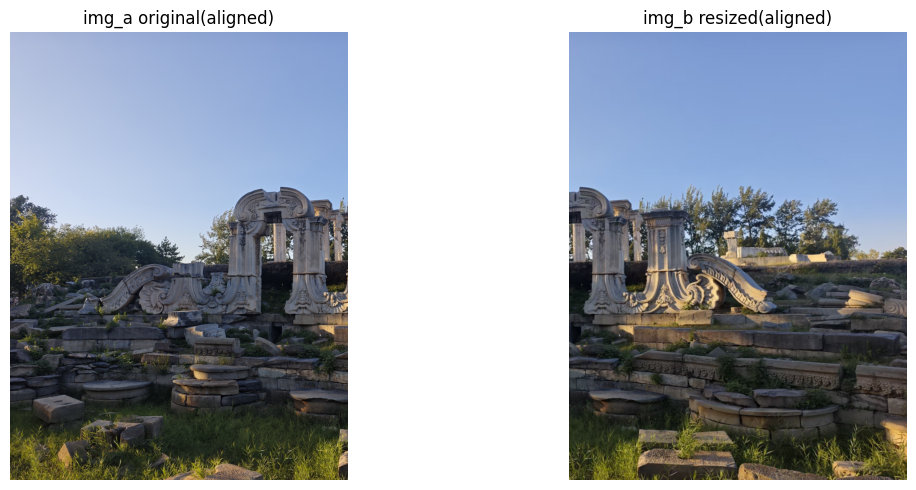

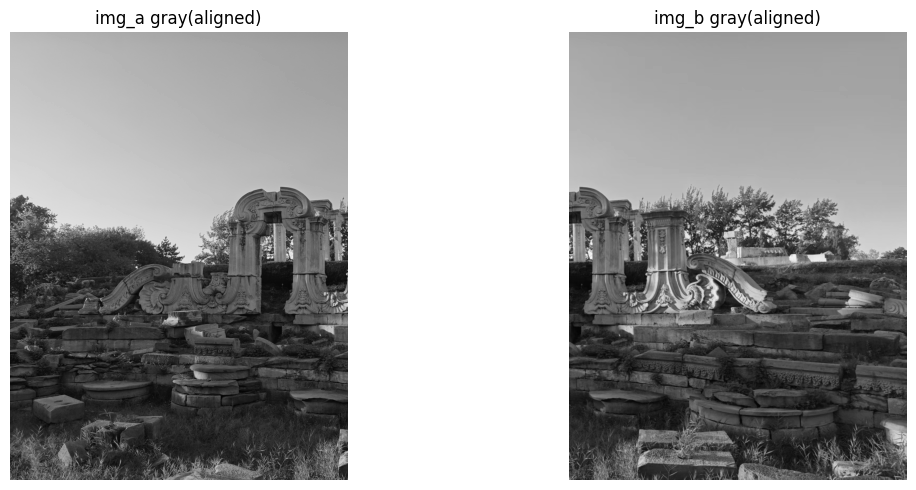

In [27]:
#附加：resize强制对齐尺寸，消除黑块
img_a = cv2.imread("p1.jpg")
img_b = cv2.imread("p2.jpg")

print(f"对齐前 img_a h,w = {img_a.shape[:2]}")
print(f"对齐前 img_b h,w = {img_b.shape[:2]}")

h_a, w_a = img_a.shape[:2]
img_b = cv2.resize(img_b, (w_a, h_a))

gray_a = cv2.cvtColor(img_a, cv2.COLOR_BGR2GRAY)
gray_b = cv2.cvtColor(img_b, cv2.COLOR_BGR2GRAY)

print(f"对齐后 img_a h,w = {img_a.shape[:2]}")
print(f"对齐后 img_b h,w = {img_b.shape[:2]}")

# 彩色图
plt.figure(figsize=(13,5))
plt.subplot(1,2,1)
plt.imshow(cv2.cvtColor(img_a, cv2.COLOR_BGR2RGB))
plt.title("img_a original(aligned)")
plt.axis("off")

plt.subplot(1,2,2)
plt.imshow(cv2.cvtColor(img_b, cv2.COLOR_BGR2RGB))
plt.title("img_b resized(aligned)")
plt.axis("off")
plt.tight_layout()
plt.savefig(os.path.join("result","input_rgb_aligned.jpg"),bbox_inches="tight")
plt.show()

# 灰度图
plt.figure(figsize=(13,5))
plt.subplot(1,2,1)
plt.imshow(gray_a, cmap="gray")
plt.title("img_a gray(aligned)")
plt.axis("off")

plt.subplot(1,2,2)
plt.imshow(gray_b, cmap="gray")
plt.title("img_b gray(aligned)")
plt.axis("off")
plt.tight_layout()
plt.savefig(os.path.join("result","input_gray_aligned.jpg"),bbox_inches="tight")
plt.show()



=== 特征匹配统计 ===
初始匹配点对数: 49470
筛选后优质匹配点对数: 1037
优质匹配占比: 2.10%


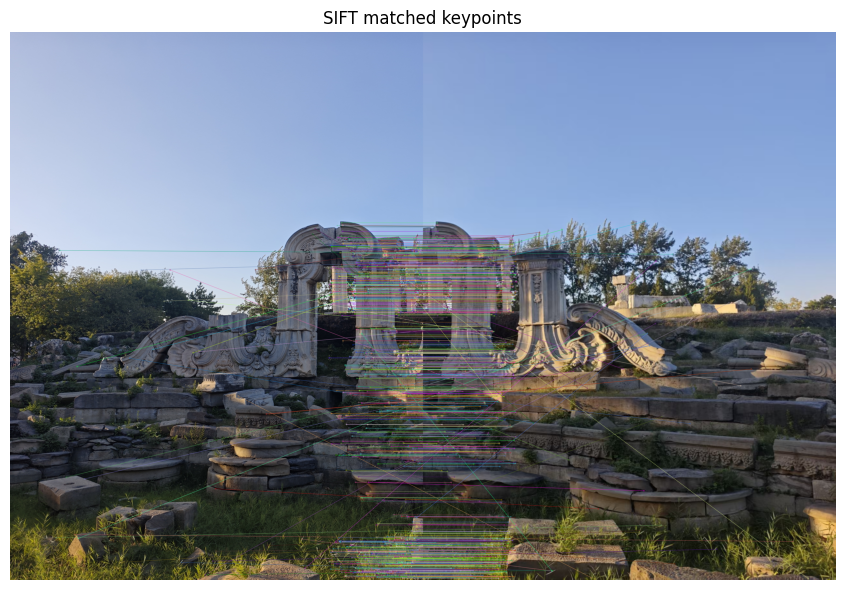

In [29]:
#关键点检测、特征匹配
sift = cv2.SIFT_create()
kp_a, des_a = sift.detectAndCompute(gray_a, None)
kp_b, des_b = sift.detectAndCompute(gray_b, None)

bf = cv2.BFMatcher()
matches = bf.knnMatch(des_a, des_b, k=2)

good_matches = []
for m, n in matches:
    if m.distance < 0.7 * n.distance:
        good_matches.append(m)

print("=== 特征匹配统计 ===")
print(f"初始匹配点对数: {len(matches)}")
print(f"筛选后优质匹配点对数: {len(good_matches)}")
if len(matches) > 0:
    print(f"优质匹配占比: {len(good_matches)/len(matches):.2%}")

matched_img = cv2.drawMatches(
    img_a, kp_a, img_b, kp_b, good_matches,
    None, flags=cv2.DrawMatchesFlags_NOT_DRAW_SINGLE_POINTS
)

plt.figure(figsize=(16,6))
plt.imshow(cv2.cvtColor(matched_img, cv2.COLOR_BGR2RGB))
plt.title("SIFT matched keypoints")
plt.axis("off")
plt.tight_layout()
plt.savefig(os.path.join("result","matched_keypoints_2.jpg"),bbox_inches="tight")
plt.show()


得到单应矩阵H:
[[ 9.98598726e-01 -2.35468464e-04  1.77981874e+03]
 [-1.82010481e-04  9.98838775e-01  6.25728648e-01]
 [-1.29657115e-07 -1.23450099e-07  1.00000000e+00]]


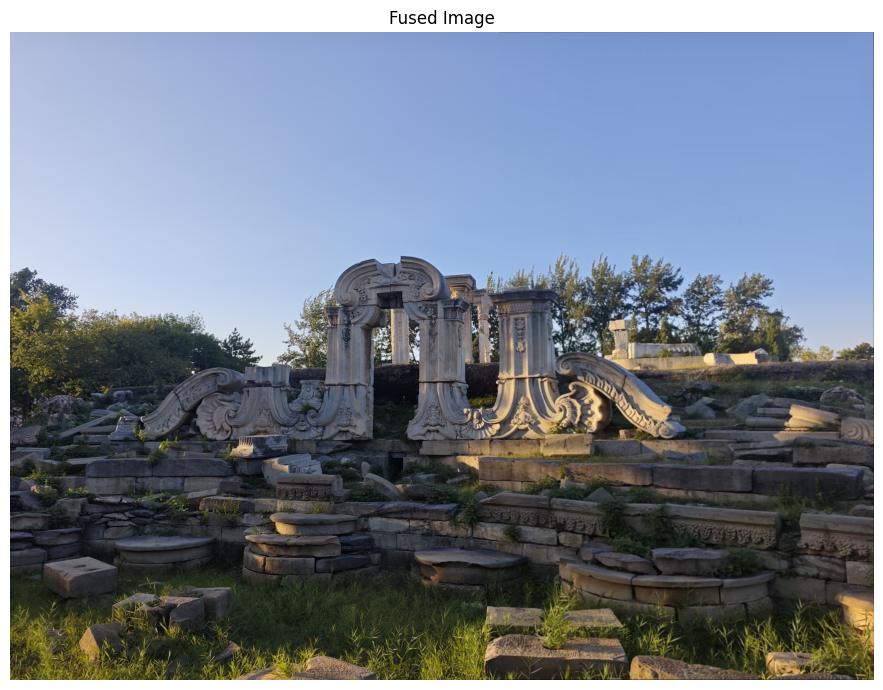

In [30]:
#图像拼接
src_pts = np.float32([kp_b[m.trainIdx].pt for m in good_matches]).reshape(-1,1,2)
dst_pts = np.float32([kp_a[m.queryIdx].pt for m in good_matches]).reshape(-1,1,2)

H, mask = cv2.findHomography(src_pts, dst_pts, cv2.RANSAC, 5.0)
print("\n得到单应矩阵H:")
print(H)

h_a, w_a = img_a.shape[:2]
h_b, w_b = img_b.shape[:2]

pts = np.float32([[0,0],[0,h_b],[w_b,h_b],[w_b,0]]).reshape(-1,1,2)
dst_corners = cv2.perspectiveTransform(pts, H)

all_corners = np.concatenate([dst_corners, np.float32([[0,0],[w_a,0],[w_a,h_a],[0,h_a]]).reshape(-1,1,2)])
[x_min, y_min] = np.int32(all_corners.min(axis=0).ravel() + 0.5)
[x_max, y_max] = np.int32(all_corners.max(axis=0).ravel() + 0.5)

trans_mat = np.array([[1,0,-x_min],[0,1,-y_min],[0,0,1]], dtype=np.float32)

fus_img = cv2.warpPerspective(img_b, trans_mat @ H, (x_max - x_min, y_max - y_min))
fus_img[-y_min : h_a - y_min, -x_min : w_a - x_min] = img_a

plt.figure(figsize=(18,7))
plt.imshow(cv2.cvtColor(fus_img, cv2.COLOR_BGR2RGB))
plt.title("Fused Image")
plt.axis("off")
plt.tight_layout()
plt.savefig(os.path.join("result","stitched_result_2.jpg"),bbox_inches="tight")
plt.show()
